# From a Clinical Note Image to AI-Ready Data

**Learning path:** synthetic note image → OCR → clinical NLP / local LLM → structured JSON → clinical checks → Pandas tables → candidate AI-ready features.

**Safety / provenance:** All content in this notebook is fictional and created here. It is **not** derived from any Synthea patient or a real person's medical record. The methods illustrate extraction and quality checks; they are **not validated for clinical use**. No patient data is sent to remote services. The optional LLM runs on your own machine via Ollama.

## 0. Setup

From Terminal (macOS):

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install jupyter pandas pillow matplotlib pytesseract requests
# Optional OCR engine: brew install tesseract
# Optional local LLM: install Ollama, then `ollama pull llama3.2:3b` and `ollama serve`
jupyter notebook
```

The Python library `pytesseract` is only a wrapper; the `tesseract` binary must be installed separately. Optional LLM mode uses `http://localhost:11434/api/generate`. You can change the model name below. On systems without the optional tools, the notebook uses a clearly marked **reference demonstration** instead of claiming that OCR or an LLM ran.

In [1]:
from pathlib import Path
import json, re, shutil, textwrap
import pandas as pd
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

OUTPUT_DIR = Path('clinical_note_demo_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
USE_OLLAMA = False  # Change to True only when Ollama is installed and running
OLLAMA_MODEL = 'llama3.2:3b'
NOTE_PATH = OUTPUT_DIR / 'synthetic_clinical_note.png'
print('Outputs:', OUTPUT_DIR.resolve())

Outputs: /Users/lakshmi/healthtech-playground/clinical_note_demo_outputs


## 1. Create and display a synthetic scanned-note image

This is an **illustrative clinical note**, intentionally authored for the talk. A real document can contain handwriting, stamps, layouts, PHI, and OCR artifacts; this clean image is intended for teaching the processing stages.

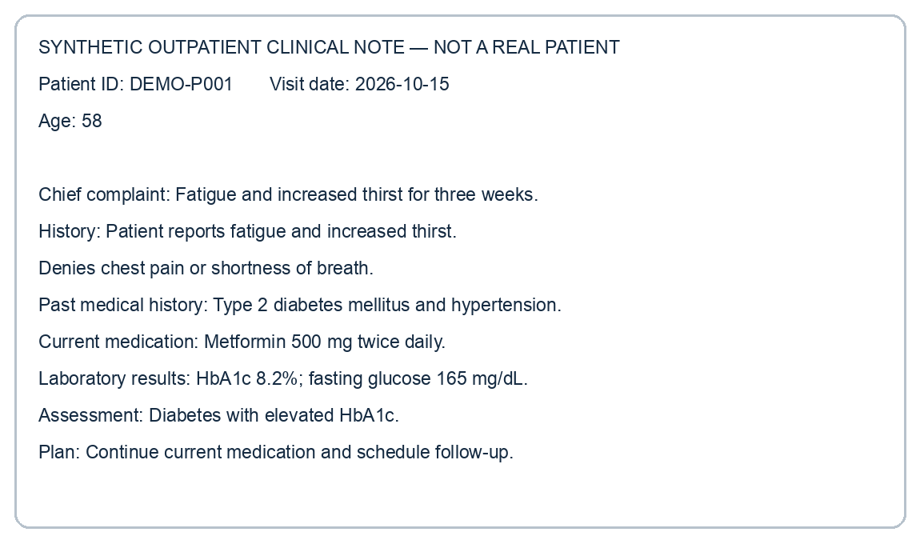

Created: clinical_note_demo_outputs/synthetic_clinical_note.png


In [2]:
NOTE_LINES = [
    'SYNTHETIC OUTPATIENT CLINICAL NOTE — NOT A REAL PATIENT',
    'Patient ID: DEMO-P001       Visit date: 2026-10-15',
    'Age: 58',
    '',
    'Chief complaint: Fatigue and increased thirst for three weeks.',
    'History: Patient reports fatigue and increased thirst.',
    'Denies chest pain or shortness of breath.',
    'Past medical history: Type 2 diabetes mellitus and hypertension.',
    'Current medication: Metformin 500 mg twice daily.',
    'Laboratory results: HbA1c 8.2%; fasting glucose 165 mg/dL.',
    'Assessment: Diabetes with elevated HbA1c.',
    'Plan: Continue current medication and schedule follow-up.',
]
# Render text as PNG without external fonts or files.
font_path = next((x for x in [
    '/System/Library/Fonts/Supplemental/Arial.ttf',
    '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
    '/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf'
] if Path(x).exists()), None)
font = ImageFont.truetype(font_path, 23) if font_path else ImageFont.load_default()
img = Image.new('RGB', (1150, 680), 'white')
draw = ImageDraw.Draw(img)
draw.rounded_rectangle((18, 18, 1132, 660), radius=18, outline='#b7c2cc', width=3)
for i, line in enumerate(NOTE_LINES):
    draw.text((48, 46 + i * 46), line, font=font, fill='#152b42')
img.save(NOTE_PATH)
display(img.resize((920, 544)))
print('Created:', NOTE_PATH)


### Can we directly join the information in this image to our patients, encounters, and observations tables?

Not reliably right. First we must digitize the text, identify concepts, preserve negation and timing, validate the extraction, and maintain provenance.

## 2. OCR: pixels → text

We attempt OCR using Tesseract. When it is unavailable, we use the **known original source text** used to draw this synthetic image.

In [4]:
SOURCE_NOTE = '\n'.join(NOTE_LINES)
try:
    import pytesseract
    if shutil.which('tesseract') is None:
        raise RuntimeError('Tesseract OCR executable not installed')
    extracted_text = pytesseract.image_to_string(Image.open(NOTE_PATH))
    if not extracted_text.strip():
        raise RuntimeError('OCR returned no text')
    ocr_mode = 'TESSERACT OCR ACTUALLY EXECUTED'
except (ImportError, RuntimeError, OSError) as exc:
    extracted_text = SOURCE_NOTE
    ocr_mode = f'SOURCE-TEXT FALLBACK (OCR NOT EXECUTED: {exc})'
print(ocr_mode)
print('-' * 65)
print(extracted_text)
(OUTPUT_DIR / 'extracted_note.txt').write_text(extracted_text, encoding='utf-8')

TESSERACT OCR ACTUALLY EXECUTED
-----------------------------------------------------------------
SYNTHETIC OUTPATIENT CLINICAL NOTE — NOT AREAL PATIENT
Patient ID: DEMO-P001 Visit date: 2026-10-15
Age: 58

Chief complaint: Fatigue and increased thirst for three weeks.
History: Patient reports fatigue and increased thirst.

Denies chest pain or shortness of breath.

Past medical history: Type 2 diabetes mellitus and hypertension.
Current medication: Metformin 500 mg twice daily.

Laboratory results: HbA1c 8.2%; fasting glucose 165 mg/dL.
Assessment: Diabetes with elevated HbA‘1c.

Plan: Continue current medication and schedule follow-up.



548

## 3. What should structured extraction preserve?

At minimum: source text evidence, patient / encounter context, assertion status (**present vs negated**), measurements **with units**, medication dose and frequency, note date, and extraction provenance. A keyword finder that says “chest pain = yes” would be incorrect here: the patient **denies** it.

In [5]:
EXTRACTION_SCHEMA = {
    'patient_id': 'string', 'visit_date': 'YYYY-MM-DD',
    'symptoms': [{'name':'string','assertion':'present|negated|uncertain|historical','evidence':'verbatim quote'}],
    'conditions': [{'name':'string','assertion':'present|negated|uncertain|historical','evidence':'verbatim quote'}],
    'medications': [{'name':'string','dose':'string|null','frequency':'string|null','evidence':'verbatim quote'}],
    'observations': [{'name':'string','value':'number','unit':'string','evidence':'verbatim quote'}],
}
print(json.dumps(EXTRACTION_SCHEMA, indent=2))

{
  "patient_id": "string",
  "visit_date": "YYYY-MM-DD",
  "symptoms": [
    {
      "name": "string",
      "assertion": "present|negated|uncertain|historical",
      "evidence": "verbatim quote"
    }
  ],
  "conditions": [
    {
      "name": "string",
      "assertion": "present|negated|uncertain|historical",
      "evidence": "verbatim quote"
    }
  ],
  "medications": [
    {
      "name": "string",
      "dose": "string|null",
      "frequency": "string|null",
      "evidence": "verbatim quote"
    }
  ],
  "observations": [
    {
      "name": "string",
      "value": "number",
      "unit": "string",
      "evidence": "verbatim quote"
    }
  ]
}


## 4. Reference output and optional local LLM

To make this demo reproducible without any network/model dependency, the reference extraction below is **manually curated from the synthetic source note**. It is a known-answer teaching baseline, **not an NLP or LLM result**. To actually test a local LLM, set `USE_OLLAMA = True` and run the notebook with Ollama running. We keep *both* outputs available for inspection and comparison.

In [6]:
REFERENCE_EXTRACTION = {
    'patient_id': 'DEMO-P001', 'visit_date': '2026-10-15',
    'symptoms': [
        {'name':'fatigue','assertion':'present','evidence':'fatigue'},
        {'name':'increased thirst','assertion':'present','evidence':'increased thirst'},
        {'name':'chest pain','assertion':'negated','evidence':'chest pain'},
        {'name':'shortness of breath','assertion':'negated','evidence':'shortness of breath'},
    ],
    'conditions': [
        {'name':'type 2 diabetes mellitus','assertion':'present','evidence':'Type 2 diabetes mellitus'},
        {'name':'hypertension','assertion':'present','evidence':'hypertension'},
    ],
    'medications': [
        {'name':'Metformin','dose':'500 mg','frequency':'twice daily',
         'evidence':'Metformin 500 mg twice daily'}
    ],
    'observations': [
        {'name':'HbA1c','value':8.2,'unit':'%','evidence':'HbA1c 8.2%'},
        {'name':'fasting glucose','value':165,'unit':'mg/dL','evidence':'fasting glucose 165 mg/dL'},
    ]
}

def call_ollama(note_text, model=OLLAMA_MODEL):
    import requests
    prompt = ("Extract clinical facts from the note into JSON ONLY, with the exact keys "
              "patient_id, visit_date, symptoms, conditions, medications, observations. "
              "Symptoms and conditions need name, assertion and exact evidence; "
              "medications need name, dose, frequency, evidence; "
              "observations need name, numeric value, unit, evidence. "
              "Assertions must be present, negated, uncertain or historical. "
              "Do not infer facts. Return empty arrays for absent categories.\n\nNOTE:\n" + note_text)
    response = requests.post('http://127.0.0.1:11434/api/generate',
        json={'model':model,'prompt':prompt,'stream':False,'format':'json'}, timeout=120)
    response.raise_for_status()
    return json.loads(response.json()['response'])

if USE_OLLAMA:
    try:
        extracted = call_ollama(extracted_text)
        extraction_mode = f'LOCAL OLLAMA LLM: {OLLAMA_MODEL}'
    except Exception as exc:
        print(f'Local LLM unavailable: {exc}')
        extracted = REFERENCE_EXTRACTION.copy()
        extraction_mode = 'MANUALLY CURATED REFERENCE FALLBACK; NO LLM INFERENCE'
else:
    extracted = REFERENCE_EXTRACTION.copy()
    extraction_mode = 'MANUALLY CURATED REFERENCE; NO LLM INFERENCE'
print(extraction_mode)
print(json.dumps(extracted, indent=2))

MANUALLY CURATED REFERENCE; NO LLM INFERENCE
{
  "patient_id": "DEMO-P001",
  "visit_date": "2026-10-15",
  "symptoms": [
    {
      "name": "fatigue",
      "assertion": "present",
      "evidence": "fatigue"
    },
    {
      "name": "increased thirst",
      "assertion": "present",
      "evidence": "increased thirst"
    },
    {
      "name": "chest pain",
      "assertion": "negated",
      "evidence": "chest pain"
    },
    {
      "name": "shortness of breath",
      "assertion": "negated",
      "evidence": "shortness of breath"
    }
  ],
  "conditions": [
    {
      "name": "type 2 diabetes mellitus",
      "assertion": "present",
      "evidence": "Type 2 diabetes mellitus"
    },
    {
      "name": "hypertension",
      "assertion": "present",
      "evidence": "hypertension"
    }
  ],
  "medications": [
    {
      "name": "Metformin",
      "dose": "500 mg",
      "frequency": "twice daily",
      "evidence": "Metformin 500 mg twice daily"
    }
  ],
  "observation

## 5. Validation: JSON shape, evidence, negation and units

A valid JSON response is not necessarily clinically accurate. The checks below catch missing fields, unsupported source quotes, wrong datatypes, and obvious assertion/measurement mismatches. These checks are deliberately narrow and **cannot certify clinical correctness**.

In [7]:
def validate_extraction(record, source_note):
    problems = []
    for key in ('patient_id','visit_date','symptoms','conditions','medications','observations'):
        if key not in record: problems.append(f'Missing top-level key: {key}')
    if problems: return problems
    for field in ('symptoms','conditions','medications','observations'):
        if not isinstance(record[field], list):
            problems.append(f'{field} should be a list')
            continue
        for idx, item in enumerate(record[field]):
            if not isinstance(item, dict):
                problems.append(f'{field}[{idx}] is not an object'); continue
            evidence = item.get('evidence')
            if not isinstance(evidence, str) or not evidence.strip():
                problems.append(f'{field}[{idx}] lacks evidence')
            elif evidence.casefold() not in source_note.casefold():
                problems.append(f'{field}[{idx}] evidence not found verbatim')
            if field in ('symptoms','conditions') and item.get('assertion') not in ('present','negated','uncertain','historical'):
                problems.append(f'{field}[{idx}] invalid assertion')
            if field == 'observations' and (not isinstance(item.get('value'), (int,float)) or not item.get('unit')):
                problems.append(f'{field}[{idx}] value/unit invalid')
    if record.get('patient_id') not in source_note:
        problems.append('patient_id not supported by note')
    if record.get('visit_date') not in source_note:
        problems.append('visit_date not supported by note')
    return problems

issues = validate_extraction(extracted, extracted_text)
print('Extraction validation:', 'PASS (basic checks only)' if not issues else 'NEEDS REVIEW')
for issue in issues: print(' •', issue)
# Test fixture: chest pain must not be encoded as a present symptom
chest_pain = [s for s in extracted.get('symptoms', []) if s.get('name','').lower() == 'chest pain']
print('Chest pain assertions:', [s.get('assertion') for s in chest_pain])
print('Expected assertion: negated (because the note says "Denies chest pain")')

Extraction validation: PASS (basic checks only)
Chest pain assertions: ['negated']
Expected assertion: negated (because the note says "Denies chest pain")


### A failure

A simplistic rule `"chest pain" in note` incorrectly flags chest pain as present. Negation, uncertainty, family history, and timing are not optional for healthcare NLP. Also note that quoting only a short entity (“chest pain”) doesn't establish the assertion; the *full surrounding sentence* matters. An operational system would use evidence spans and trained clinical validation.

In [8]:
naive_positive = 'chest pain' in extracted_text.lower()
validated_status = next((s.get('assertion') for s in extracted.get('symptoms', [])
                         if s.get('name','').lower() == 'chest pain'), None)
print('Naive keyword match, chest pain present?', naive_positive)
print('Context-aware output, chest pain assertion:', validated_status)

Naive keyword match, chest pain present? True
Context-aware output, chest pain assertion: negated


## 6. Convert extracted JSON into Pandas tables

We preserve the `assertion` and `evidence` fields instead of reducing findings to unqualified binary flags. We also attach `note_id`, `visit_date`, `source_file`, and extraction method as basic provenance.

In [9]:
note_id = 'DEMO-NOTE-001'
provenance = {'patient_id':extracted.get('patient_id'), 'visit_date':extracted.get('visit_date'),
              'note_id':note_id, 'source_file':NOTE_PATH.name, 'extraction_method':extraction_mode}

def as_table(section):
    df = pd.DataFrame(extracted.get(section, []))
    for key, val in provenance.items(): df[key] = val
    return df
symptoms_df = as_table('symptoms')
conditions_df = as_table('conditions')
medications_df = as_table('medications')
observations_df = as_table('observations')
for label, df in [('Symptoms',symptoms_df),('Conditions',conditions_df),('Medications',medications_df),('Observations',observations_df)]:
    print('\n',label)
    display(df)
    df.to_csv(OUTPUT_DIR / (label.lower() + '.csv'), index=False)


 Symptoms


,name,assertion,evidence,patient_id,visit_date,note_id,source_file,extraction_method
0,fatigue,present,fatigue,DEMO-P001,2026-10-15,DEMO-NOTE-001,synthetic_clinical_note.png,MANUALLY CURATED REFERENCE; NO LLM INFERENCE
1,increased thirst,present,increased thirst,DEMO-P001,2026-10-15,DEMO-NOTE-001,synthetic_clinical_note.png,MANUALLY CURATED REFERENCE; NO LLM INFERENCE
2,chest pain,negated,chest pain,DEMO-P001,2026-10-15,DEMO-NOTE-001,synthetic_clinical_note.png,MANUALLY CURATED REFERENCE; NO LLM INFERENCE
3,shortness of breath,negated,shortness of breath,DEMO-P001,2026-10-15,DEMO-NOTE-001,synthetic_clinical_note.png,MANUALLY CURATED REFERENCE; NO LLM INFERENCE



 Conditions


,name,assertion,evidence,patient_id,visit_date,note_id,source_file,extraction_method
0,type 2 diabetes mellitus,present,Type 2 diabetes mellitus,DEMO-P001,2026-10-15,DEMO-NOTE-001,synthetic_clinical_note.png,MANUALLY CURATED REFERENCE; NO LLM INFERENCE
1,hypertension,present,hypertension,DEMO-P001,2026-10-15,DEMO-NOTE-001,synthetic_clinical_note.png,MANUALLY CURATED REFERENCE; NO LLM INFERENCE



 Medications


,name,dose,frequency,evidence,patient_id,visit_date,note_id,source_file,extraction_method
0,Metformin,500 mg,twice daily,Metformin 500 mg twice daily,DEMO-P001,2026-10-15,DEMO-NOTE-001,synthetic_clinical_note.png,MANUALLY CURATED REFERENCE; NO LLM INFERENCE



 Observations


,name,value,unit,evidence,patient_id,visit_date,note_id,source_file,extraction_method
0,HbA1c,8.2,%,HbA1c 8.2%,DEMO-P001,2026-10-15,DEMO-NOTE-001,synthetic_clinical_note.png,MANUALLY CURATED REFERENCE; NO LLM INFERENCE
1,fasting glucose,165.0,mg/dL,fasting glucose 165 mg/dL,DEMO-P001,2026-10-15,DEMO-NOTE-001,synthetic_clinical_note.png,MANUALLY CURATED REFERENCE; NO LLM INFERENCE


## 7. A candidate feature row, with a fixed observation cutoff

A simple ML preparation step could produce one row per patient. We use a **fixed cutoff date**, and only notes at or before that date contribute. This matters because features must not contain future information. 

A real system also requires terminology mapping (e.g., SNOMED CT / LOINC), unit normalization, date handling, evaluation against human-annotated notes, and patient-level train/test splitting.

In [10]:
AS_OF_DATE = pd.Timestamp('2026-10-20')
visit_date = pd.to_datetime(extracted.get('visit_date'), errors='coerce')
eligible = pd.notna(visit_date) and visit_date <= AS_OF_DATE

def has_mention(df, name, assertion='present'):
    if df.empty or not {'name','assertion'}.issubset(df.columns): return 0
    return int(((df['name'].astype(str).str.casefold() == name.casefold()) &
                (df['assertion'] == assertion)).any())

def numeric_observation(df, name, unit):
    if df.empty or not {'name','value','unit'}.issubset(df.columns): return None
    hits = df[(df['name'].astype(str).str.casefold() == name.casefold()) & (df['unit'] == unit)]
    if hits.empty: return None
    return float(pd.to_numeric(hits.iloc[0]['value'], errors='coerce'))

if eligible and not issues:
    feature_row = {
        'patient_id':extracted['patient_id'], 'as_of_date':AS_OF_DATE.date().isoformat(),
        'fatigue_present':has_mention(symptoms_df,'fatigue'),
        'chest_pain_negated':has_mention(symptoms_df,'chest pain','negated'),
        'diabetes_documented':has_mention(conditions_df,'type 2 diabetes mellitus'),
        'hba1c_percent':numeric_observation(observations_df,'HbA1c','%'),
        'fasting_glucose_mg_dl':numeric_observation(observations_df,'fasting glucose','mg/dL'),
        'source_note_id':note_id,
    }
    features = pd.DataFrame([feature_row])
    display(features)
    features.to_csv(OUTPUT_DIR / 'candidate_ai_features.csv', index=False)
else:
    features = pd.DataFrame()
    print('Feature creation withheld: failed validation or note is after cutoff')
print('Eligible by timestamp:', eligible, '| Basic validation passed:', not issues)

,patient_id,as_of_date,fatigue_present,chest_pain_negated,diabetes_documented,hba1c_percent,fasting_glucose_mg_dl,source_note_id
0,DEMO-P001,2026-10-20,1,1,1,8.2,165.0,DEMO-NOTE-001


Eligible by timestamp: True | Basic validation passed: True


## 8. Data leakage test

Even a perfectly extracted note must be excluded if written *after* the model's prediction date. This is one of the most common errors in healthcare feature engineering.

In [11]:
past_cutoff = pd.Timestamp('2026-10-01')
print('Note date:', visit_date.date(), '| Earlier prediction cutoff:', past_cutoff.date())
print('Should this note contribute to features at the earlier cutoff?', bool(visit_date <= past_cutoff))
assert visit_date > past_cutoff, 'Illustrative date should be after the earlier cutoff'
assert has_mention(pd.DataFrame(REFERENCE_EXTRACTION['symptoms']), 'chest pain','negated') == 1
print('Demonstration checks passed')

Note date: 2026-10-15 | Earlier prediction cutoff: 2026-10-01
Should this note contribute to features at the earlier cutoff? False
Demonstration checks passed


## 9. What makes the output *actually* AI-ready?

We have demonstrated how an unstructured image can become **candidate structured data**. For clinical-grade use, the remaining work includes:

1. **OCR quality:** measure character/field accuracy on a curated set of note images.
2. **Clinical extraction quality:** evaluate precision/recall on annotated entities *and assertion states*.
3. **Terminology and units:** map concepts to appropriate codes; standardize units without changing meaning.
4. **Temporal semantics:** distinguish visit date, onset, historical conditions, and future instructions.
5. **Provenance:** retain document identifiers, version, extraction model, evidence spans, and review decisions.
6. **Privacy:** synthetic-only for demos; real patient documents require proper access control and a compliant processing environment.
7. **Model evaluation:** split by patient and time as appropriate, prevent leakage, and assess clinical applicability.

### Closing takeaway

> **Making healthcare data AI-ready is not just recognizing words. It means preserving clinical meaning, context, provenance, and time.**